In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
norms_L1 = pd.read_csv('norms_L1.csv', index_col=0)
norms_L2 = pd.read_csv('norms_L2.csv', index_col=0)
norms_max = pd.read_csv('norms_max.csv', index_col=0)

rel_norms_L1 = pd.read_csv('rel_norms_L1.csv', index_col=0)
rel_norms_L2 = pd.read_csv('rel_norms_L2.csv', index_col=0)
rel_norms_max = pd.read_csv('rel_norms_max.csv', index_col=0)

w_rel_norms_L1 = pd.read_csv('w_rel_norms_L1.csv', index_col=0)
w_rel_norms_L2 = pd.read_csv('w_rel_norms_L2.csv', index_col=0)
w_rel_norms_max = pd.read_csv('w_rel_norms_max.csv', index_col=0)

In [10]:
pd.DataFrame({
    'L1': norms_L1.mean(), 'L2': norms_L2.mean(), 'max': norms_max.mean(),
    'rel_L1': rel_norms_L1.mean(), 'rel_L2': rel_norms_L2.mean(), 'rel_max': rel_norms_max.mean(),
    'w_rel_L1': 100*w_rel_norms_L1.mean(), 'w_rel_L2': 100*w_rel_norms_L2.mean(), 'w_rel_max': 100*w_rel_norms_max.mean()
})

,L1,L2,max,rel_L1,rel_L2,rel_max,w_rel_L1,w_rel_L2,w_rel_max
0,412.533127,14.517113,4.469790,8.355881,11.126073,16.511554,0.107304,0.315916,0.805309
1,496.691944,18.388416,7.204328,7.671638,9.272638,10.789579,0.043810,0.167645,0.529990
2,679.819115,19.324569,2.763289,8.538232,8.421093,7.433968,0.023535,0.032839,0.114202
3,904.641558,25.971058,4.323604,9.987702,9.823297,8.404168,0.018205,0.024466,0.060244
4,998.149976,28.535166,4.840937,9.931682,9.829225,9.509250,0.011505,0.012920,0.025882
5,1123.028738,31.641284,4.509568,10.473003,10.246060,9.149375,0.008368,0.009103,0.018913
6,1275.780357,36.316221,6.553882,11.247189,10.831384,10.372708,0.006578,0.007397,0.015663
7,1459.292892,52.295473,23.943427,12.264565,13.745131,20.516824,0.005319,0.006394,0.010594
8,1761.262764,50.885283,10.507699,13.464531,12.994005,10.101384,0.004601,0.004935,0.006794
9,1873.508682,57.390542,18.661073,14.116570,14.217177,15.308393,0.005217,0.006490,0.009772


# Router results

In [2]:
block_pruner = pd.read_csv('results/results_block_pruner.csv', index_col=0)
block_pruner['del_ratio'] = block_pruner.index / 24
wrell2 = pd.read_csv('results/results_w_rel_L2.csv', index_col=0)
wrell2['del_ratio'] = wrell2.index / 24

small_changes = pd.read_csv('results/results_threshold_rel_except.csv', index_col=0, header=[0, 1])
small_changes = small_changes.loc[:, [('perplexity', 'L1'), ('ratio_del', 'L1')]]

results = {}
results['r'] = pd.read_csv('results/results_router.csv', index_col=0)
results['topk'] = pd.read_csv('results/results_router_topk.csv', index_col=[0, 1])
results['thr'] = pd.read_csv('results/results_router_thr.csv', index_col=0)
results['singleskip'] = pd.read_csv('results/results_singleskip_router.csv', index_col=0)
results['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk.csv', index_col=[0, 1])
results['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router.csv', index_col=0)

results_v2 = {}
results_v2['r'] = pd.read_csv('results/results_router_v2.csv', index_col=0)
results_v2['thr'] = pd.read_csv('results/results_router_thr_v2.csv', index_col=0)
results_v2['singleskip'] = pd.read_csv('results/results_singleskip_router_v2.csv', index_col=0)
results_v2['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v2.csv', index_col=[0, 1])
results_v2['singleskip_rnd'] = pd.read_csv('results/results_rnd_singleskip_router_v2.csv', index_col=0)

results_v3 = {}
results_v3['singleskip'] = pd.read_csv('results/results_singleskip_router_v3ss.csv', index_col=0)
results_v3['singleskip_topk'] = pd.read_csv('results/results_router_singleskip_topk_v3ss.csv', index_col=[0, 1])

In [96]:
small_changes

,perplexity,ratio_del
norm_type,L1,L1
threshold,,
10.0,7.972623,0.084726
20.0,12.126037,0.217589
30.0,32.519547,0.369392
40.0,109.271408,0.493702
50.0,312.602570,0.581535
60.0,756.254822,0.651901
70.0,1752.414673,0.707494


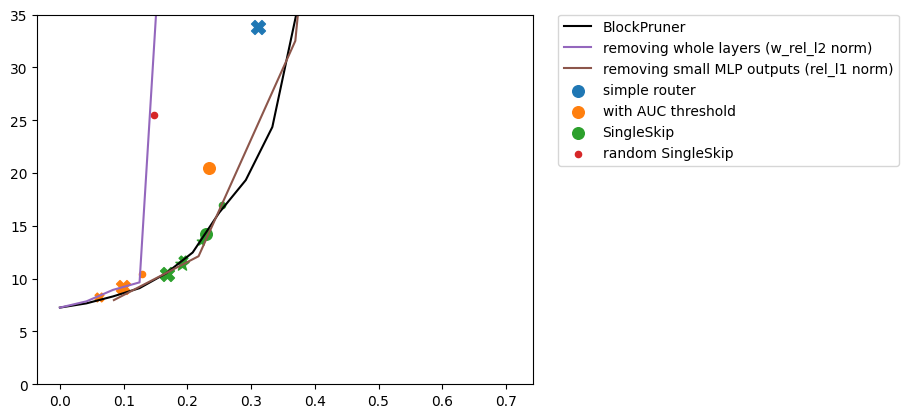

In [3]:
# plt.plot(block_pruner.del_ratio, block_pruner.perplexity)
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')
plt.plot(wrell2.loc[:13, 'del_ratio'], wrell2.loc[:13, 'perplexity'], c='tab:purple', label='removing whole layers (w_rel_l2 norm)')
plt.plot(small_changes.loc[:, 'ratio_del'], small_changes.loc[:, 'perplexity'], c='tab:brown', label='removing small MLP outputs (rel_l1 norm)')

plt.scatter(results['r'].loc['lr', 'del_ratio'], results['r'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:blue') #, label='LR router')
plt.scatter(results['r'].loc['nn', 'del_ratio'], results['r'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:blue', label='simple router') #, label='NN router')
plt.scatter(results_v2['r'].loc['lr', 'del_ratio'], results_v2['r'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:blue')
plt.scatter(results_v2['r'].loc['nn', 'del_ratio'], results_v2['r'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:blue') #, label='iteratively trained')

###

plt.scatter(results['thr'].loc['lr', 'del_ratio'], results['thr'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:orange')
plt.scatter(results['thr'].loc['nn', 'del_ratio'], results['thr'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:orange', label='with AUC threshold')
plt.scatter(results_v2['thr'].loc['lr', 'del_ratio'], results_v2['thr'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:orange')
plt.scatter(results_v2['thr'].loc['nn', 'del_ratio'], results_v2['thr'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:orange')

###

plt.scatter(results['singleskip'].loc['lr', 'del_ratio'], results['singleskip'].loc['lr', 'perplexity'], marker='o', s=20, c='tab:green')
plt.scatter(results['singleskip'].loc['nn', 'del_ratio'], results['singleskip'].loc['nn', 'perplexity'], marker='o', s=70, c='tab:green', label='SingleSkip')
plt.scatter(results_v2['singleskip'].loc['lr', 'del_ratio'], results_v2['singleskip'].loc['lr', 'perplexity'], marker='X', s=40, c='tab:green')
plt.scatter(results_v2['singleskip'].loc['nn', 'del_ratio'], results_v2['singleskip'].loc['nn', 'perplexity'], marker='X', s=100, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['lr', 'del_ratio'], results_v3['singleskip'].loc['lr', 'perplexity'], marker='*', s=40, c='tab:green')
plt.scatter(results_v3['singleskip'].loc['nn', 'del_ratio'], results_v3['singleskip'].loc['nn', 'perplexity'], marker='*', s=100, c='tab:green')

###

plt.scatter(results['singleskip_rnd'].loc[:, 'del_ratio'], results['singleskip_rnd'].loc[:, 'perplexity'], marker='o', s=20, c='tab:red', label='random SingleSkip')

plt.ylim((0, 35))
# plt.legend();
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.);


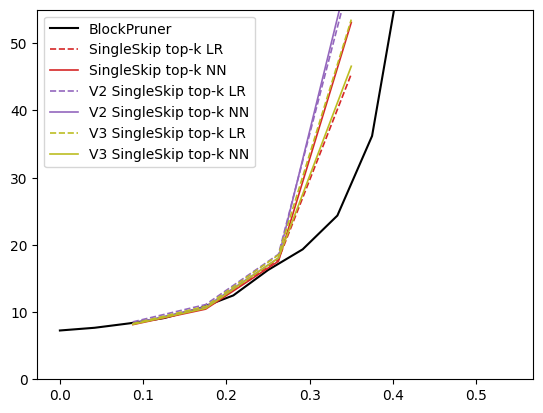

In [8]:
###
plt.plot(block_pruner.loc[:13, 'del_ratio'], block_pruner.loc[:13, 'perplexity'], c='black', label='BlockPruner')

ss_topk_lr = results['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:red', ls='--', lw=1.2, label='SingleSkip top-k LR')
ss_topk_nn = results['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:red', lw=1.2, label='SingleSkip top-k NN')

ss_topk_lr = results_v2['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:purple', ls='--', lw=1.2, label='V2 SingleSkip top-k LR')
ss_topk_nn = results_v2['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:purple', lw=1.2, label='V2 SingleSkip top-k NN')

ss_topk_lr = results_v3['singleskip_topk'].query('router_type == "lr"')
plt.plot(ss_topk_lr.del_ratio, ss_topk_lr.perplexity, c='tab:olive', ls='--', lw=1.2, label='V3 SingleSkip top-k LR')
ss_topk_nn = results_v3['singleskip_topk'].query('router_type == "nn"')
plt.plot(ss_topk_nn.del_ratio, ss_topk_nn.perplexity, c='tab:olive', lw=1.2, label='V3 SingleSkip top-k NN')

plt.ylim((0, 55))
plt.legend();